# Dogs vs Cats — Complete Image Classification Project

This notebook presents dataset inspection, leakage-aware splits, the assignment’s VGG16-style baseline, full-data transfer-learning optimization, and one final reserved-test evaluation. Detailed earlier notebooks remain alongside this report. All results below are read from executed training artifacts.


In [1]:
from pathlib import Path
import json, sys
from IPython.display import Image as DisplayImage, Markdown, display
ROOT = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
def report(name):
    return json.loads((ROOT / 'reports' / name).read_text())
def figure(name):
    display(DisplayImage(filename=str(ROOT / 'reports' / 'figures' / name)))
print('Environment:', json.dumps(report('environment_summary.json'), indent=2))


Environment: {
  "python": "3.13.18",
  "packages": {
    "tensorflow-cpu": "2.21.0",
    "keras": "3.15.1",
    "numpy": "2.5.4",
    "matplotlib": "3.11.2",
    "scikit-learn": "1.9.1",
    "Pillow": "13.0.0",
    "ipykernel": "7.4.0",
    "nbformat": "5.11.1",
    "nbclient": "0.11.0"
  },
  "tensorflow_computation": 10.0,
  "cpu_devices": 1,
  "gpu_devices": 0
}


## Dataset exploration

The course archive contains cat/dog images labeled by filename. macOS metadata companions are excluded from image counts. Original photos are preserved and raw data is excluded from Git.


labeled_images : 25000
class_counts : {'cat': 12500, 'dog': 12500}
valid_labeled_images : 25000
corrupt_count : 0
ignored_metadata_files : 25000
image_modes : {'RGB': 25000}
width_range : [42, 1050]
height_range : [32, 768]


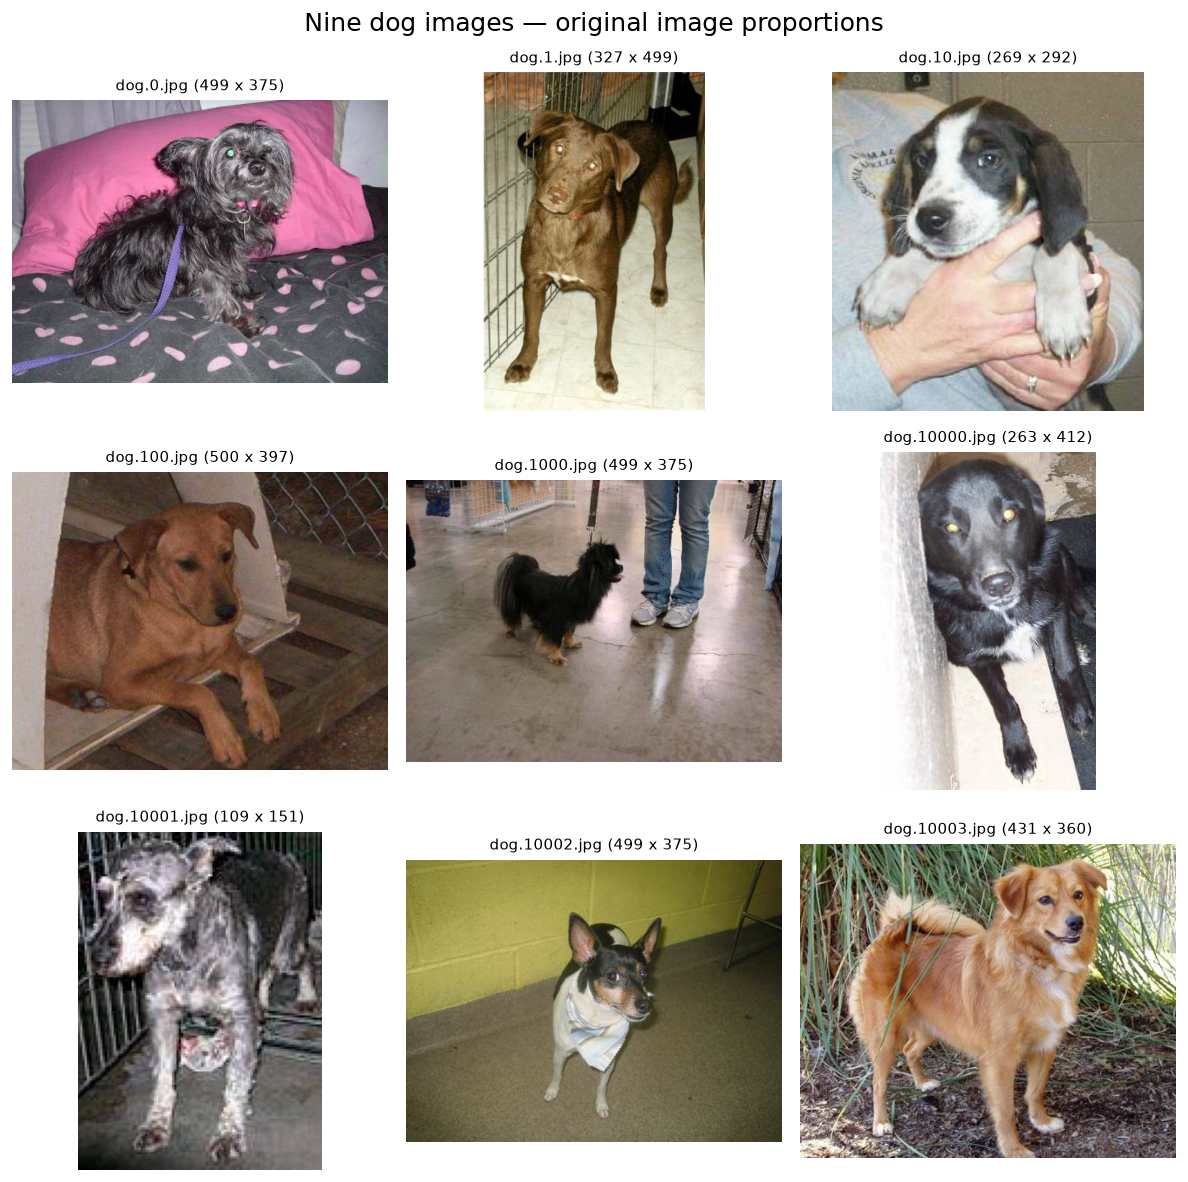

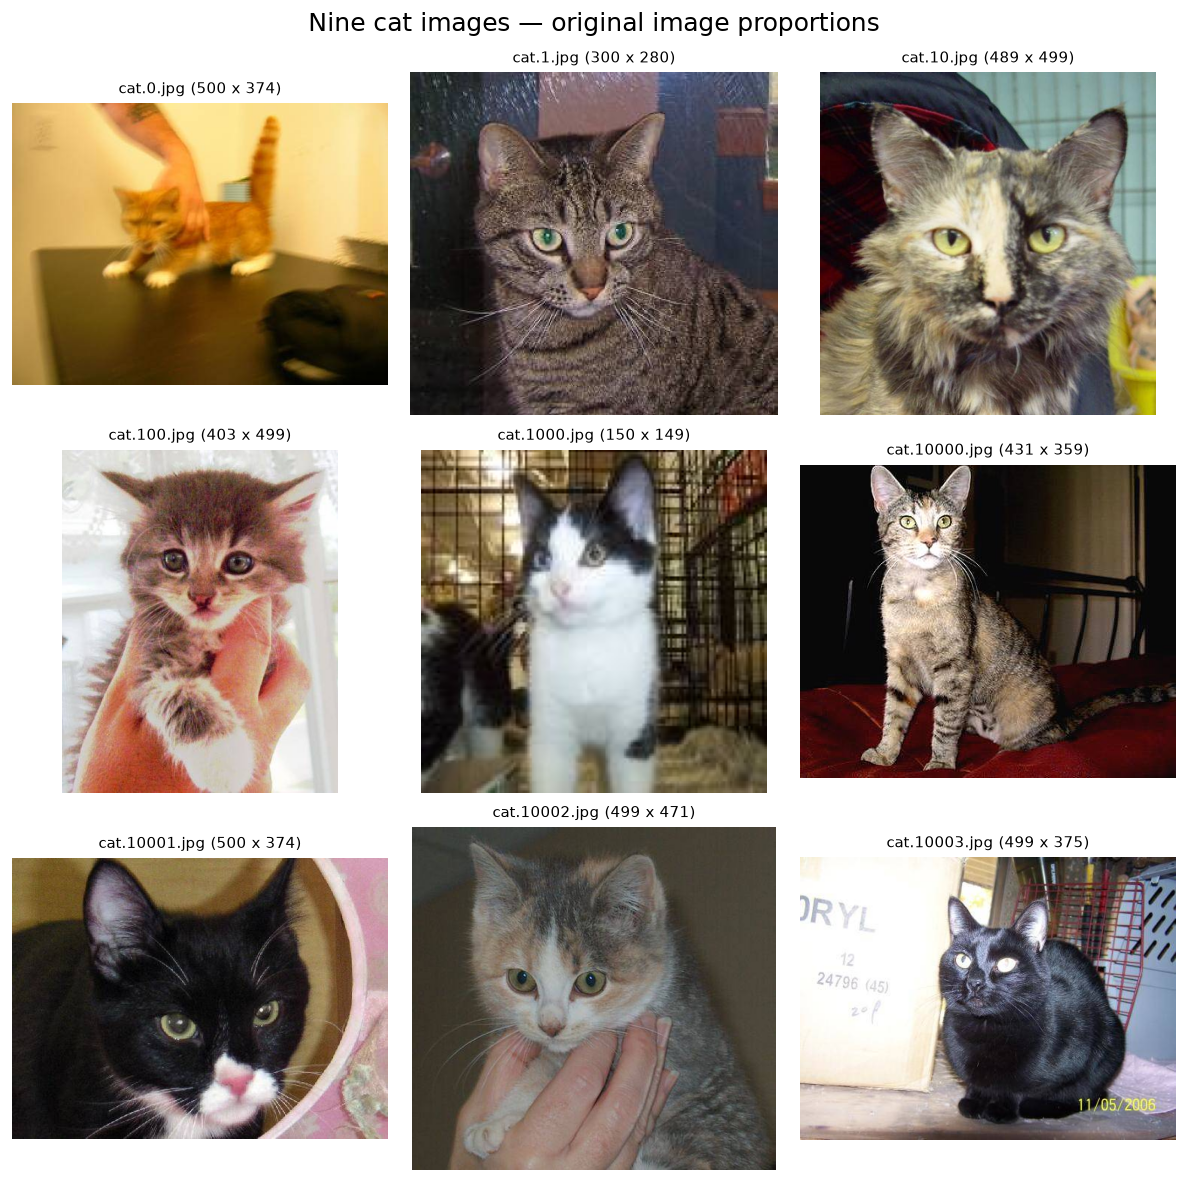

In [2]:
data = report('data_summary.json')
for key in ['labeled_images','class_counts','valid_labeled_images','corrupt_count','ignored_metadata_files','image_modes','width_range','height_range']:
    print(key, ':', data[key])
figure('dogs_grid.png')
figure('cats_grid.png')


## Data preparation

A seeded approximately 70/15/15 split groups exact duplicate content by SHA-256, preventing identical files from crossing splits. The `tf.data` loader decodes on demand, resizes to 200 × 200 RGB and normalizes pixels to [0,1]. The full pipeline was checked for every labeled image.


{
  "seed": 42,
  "requested_ratios": {
    "train": 0.7,
    "validation": 0.15,
    "test": 0.15
  },
  "label_mapping": {
    "cat": 0,
    "dog": 1
  },
  "total_images": 25000,
  "unique_content_hashes": 24994,
  "duplicate_images": 6,
  "excluded_unreadable_images": 0,
  "path_overlap": 0,
  "content_hash_overlap": 0,
  "manifest": "data/processed/split_manifest.csv",
  "manifest_sha256": "7b37b1eabab9656b3a1a8624aab4c12e64c1bc84791558ba358802c95742235d",
  "splits": {
    "train": {
      "count": 17498,
      "class_counts": {
        "cat": 8750,
        "dog": 8748
      }
    },
    "validation": {
      "count": 3748,
      "class_counts": {
        "cat": 1874,
        "dog": 1874
      }
    },
    "test": {
      "count": 3754,
      "class_counts": {
        "cat": 1876,
        "dog": 1878
      }
    }
  },
  "notes": "Exact duplicate content is kept in one split. Images are not copied. Ratios may differ slightly when duplicate groups have multiple members. The test s

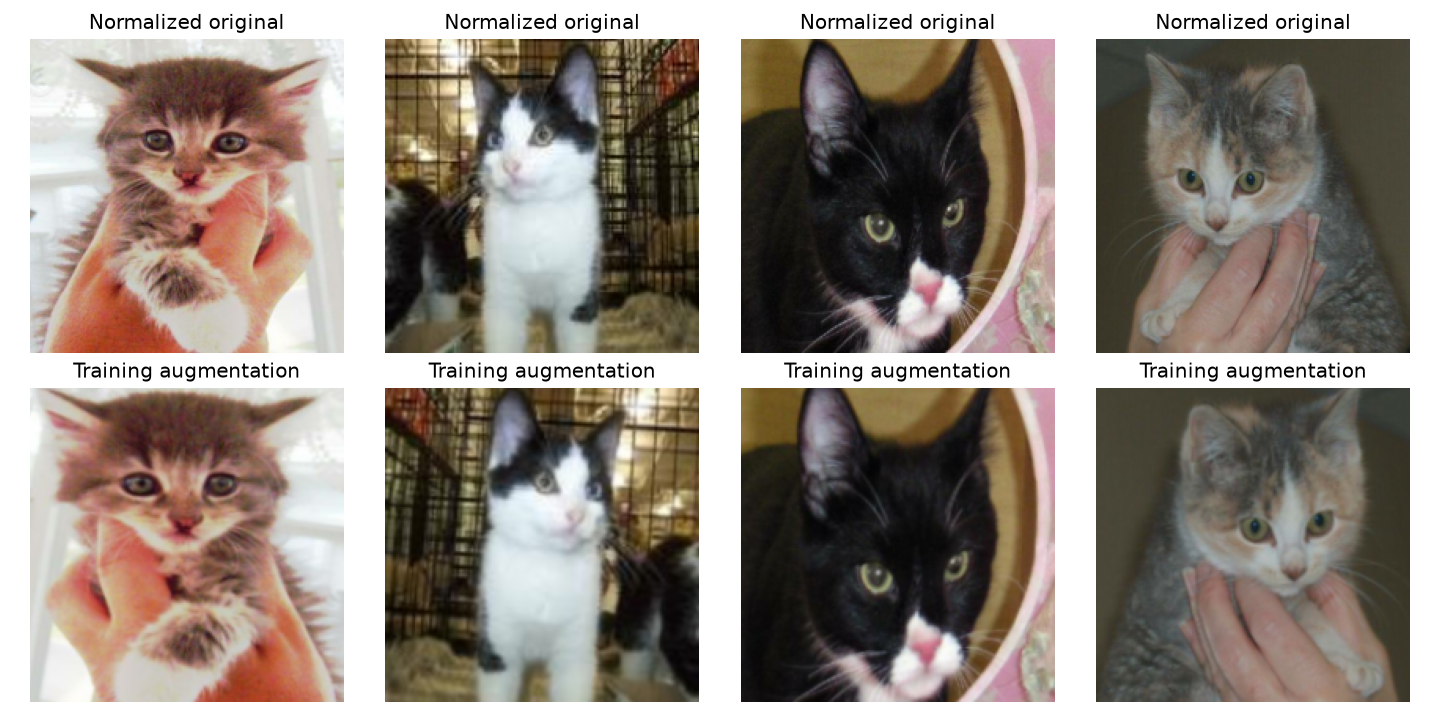

In [3]:
splits = report('split_summary.json')
print(json.dumps(splits, indent=2))
validation = report('pipeline_validation.json')
assert validation['decoded_images'] == data['labeled_images']
assert validation['content_hash_overlap'] == validation['path_overlap'] == 0
print('Loader validation:', json.dumps(validation, indent=2))
figure('preprocessing_and_augmentation.png')


## Assignment architecture and initial baseline

The baseline implements all 13 VGG16-style convolutions, five pooling layers, Flatten, two Dense(4096) layers, and a two-class softmax. Its input was made consistently 200 × 200. A small initial CPU run verified fit, saving, and reloading. **Those subset metrics are not a full-data baseline or final accuracy and are not directly comparable to the full-validation results below.**


Baseline parameters: 107005762
Initial run: training images 64 validation images 32 epochs 2
Checkpoint reload passed: True


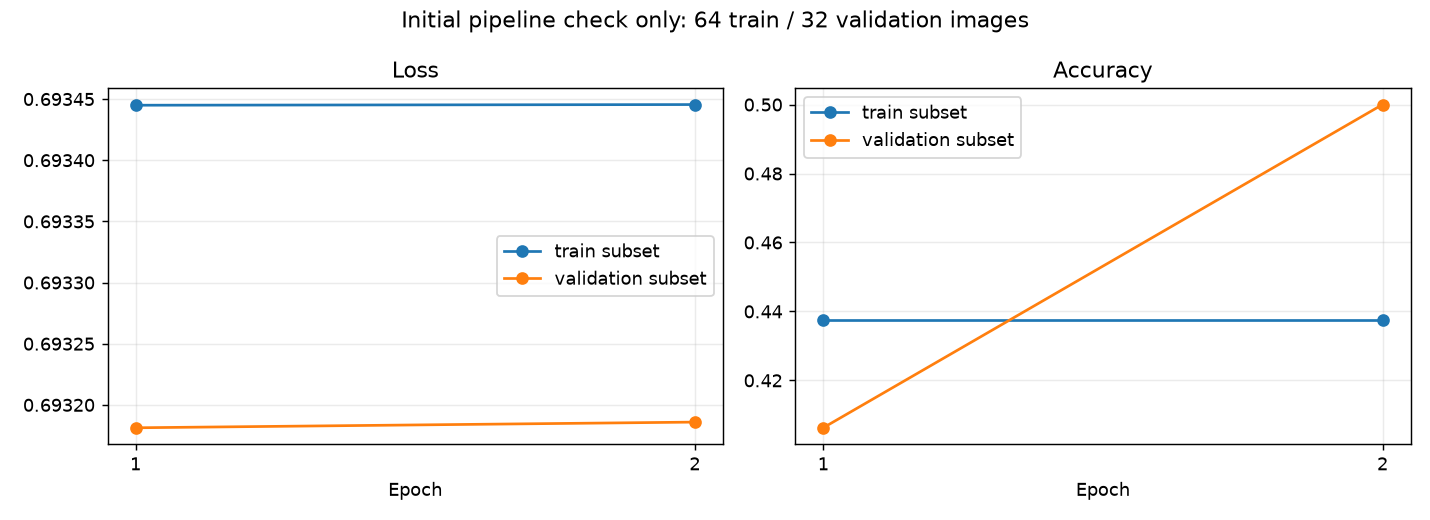

In [4]:
initial = report('initial_training_results.json')
print('Baseline parameters:', initial['parameters'])
print('Initial run: training images', initial['training_images_used'], 'validation images', initial['validation_images_used'], 'epochs', initial['epochs_completed'])
print('Checkpoint reload passed:', initial['checkpoint_reload_passed'])
figure('initial_training_history.png')


## Compute-aware optimization

The two-CPU Codespace was benchmarked before choosing the full-data approach. MobileNetV2 with ImageNet pretraining is used as the optimized alternative, while the original assignment architecture remains implemented. The convolutional base is frozen; only classifier heads are trained on all training images. Feature caching avoids repeating the frozen convolutional computation every epoch.

One seeded augmented view is added for every fourth training record. Validation and test images are never augmented. Both head candidates receive the same training views. ModelCheckpoint, EarlyStopping and ReduceLROnPlateau use validation loss; the lowest full-validation log loss selects the model before the test split is accessed.


CPU benchmark: {
  "vgg16": {
    "seconds_per_image": 0.3473189519375026,
    "estimated_train_validation_feature_minutes": 122.98564088106967,
    "parameters": 14714688,
    "feature_dimension": 512
  },
  "mobilenet_v2": {
    "seconds_per_image": 0.041752139749995365,
    "estimated_train_validation_feature_minutes": 14.784432685473359,
    "parameters": 2257984,
    "feature_dimension": 1280
  }
}
Feature extraction: {
  "backbone": "mobilenet_v2",
  "train": {
    "backbone": "mobilenet_v2",
    "weights": "imagenet",
    "split": "train",
    "original_images": 17498,
    "augmented_views": 4375,
    "rows": 21873,
    "dimensions": 1280,
    "manifest_sha256": "7b37b1eabab9656b3a1a8624aab4c12e64c1bc84791558ba358802c95742235d",
    "input_size": [
      200,
      200
    ],
    "seed": 42
  },
  "validation": {
    "backbone": "mobilenet_v2",
    "weights": "imagenet",
    "split": "validation",
    "original_images": 3748,
    "augmented_views": 0,
    "rows": 3748,
    "dime

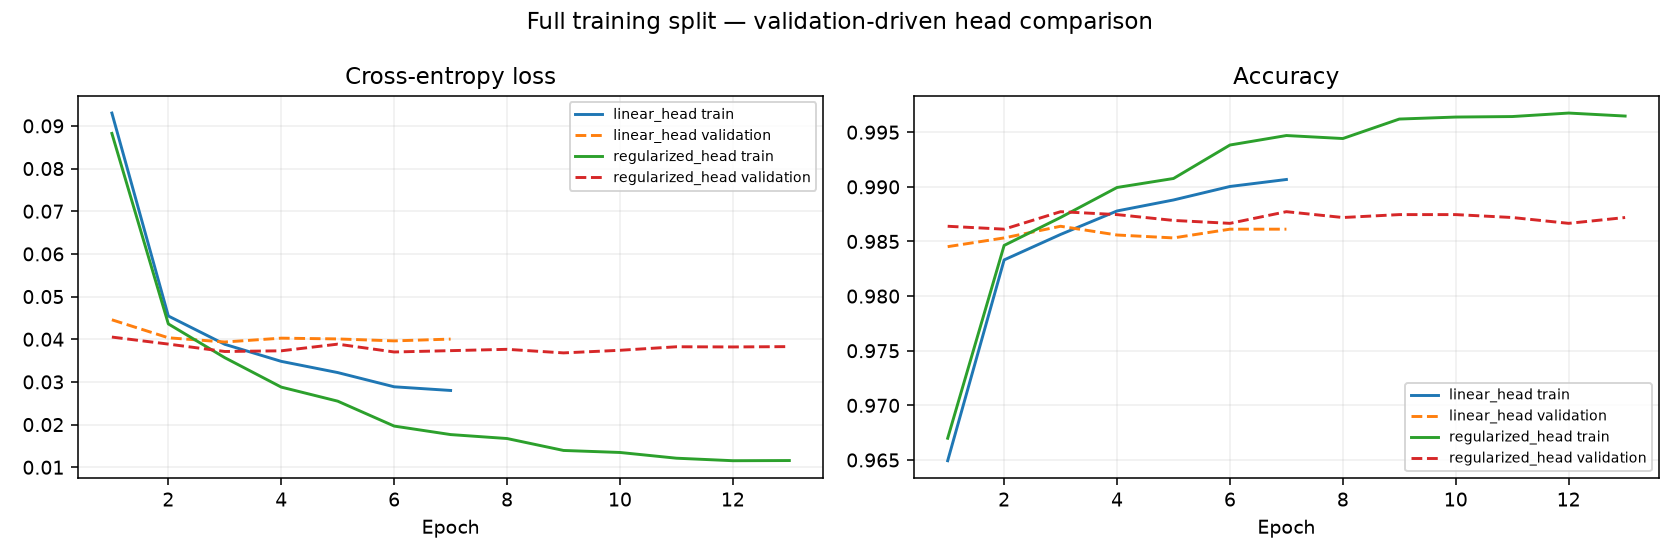

In [5]:
print('CPU benchmark:', json.dumps(report('compute_benchmark.json'), indent=2))
print('Feature extraction:', json.dumps(report('feature_extraction.json'), indent=2))
optimization = report('optimization_results.json')
for trial in optimization['trials']:
    print(trial['name'], 'epochs=', trial['epochs_completed'], 'val_accuracy=', round(trial['validation_accuracy'], 5), 'val_log_loss=', round(trial['validation_log_loss'], 5))
print('Selected:', optimization['selected']['name'])
assert not optimization['test_evaluated_during_selection']
figure('optimization_history.png')


## Final saved model

The exported model includes the frozen image backbone, its correct preprocessing, and the selected head. Its public input is normalized RGB 200 × 200, which the prediction command prepares automatically. The model is reloaded and checked against the selected head’s cached-feature predictions.


In [6]:
print(json.dumps(report('final_model_metadata.json'), indent=2))


{
  "backbone": "mobilenet_v2",
  "pretraining": "ImageNet",
  "frozen_backbone": true,
  "selected_head": "regularized_head",
  "model_path": "models/final_classifier.keras",
  "input_shape": [
    200,
    200,
    3
  ],
  "input_range": [
    0,
    1
  ],
  "class_names": [
    "cat",
    "dog"
  ],
  "parameters": 2422210,
  "bytes": 10287848,
  "sha256": "2f310e22615a3d39b30f73ca7f601348781fec06e57b038be730840e0d22bd63",
  "reload_prediction_equivalence_passed": true
}


## Reserved-test evaluation

The selected configuration was locked using validation results before testing. The test set is used once here for final reporting; it is not used for early stopping, architecture choice, learning-rate changes, or threshold tuning. The decision rule is the argmax of two softmax probabilities.


Test photos: 3754
Accuracy: 98.48%
ROC AUC: 0.99881
Log loss: 0.0419
cat {'precision': 0.9804543053354464, 'recall': 0.9893390191897654, 'f1-score': 0.9848766250994959, 'support': 1876.0}
dog {'precision': 0.9892530897367007, 'recall': 0.9802981895633652, 'f1-score': 0.9847552821610056, 'support': 1878.0}


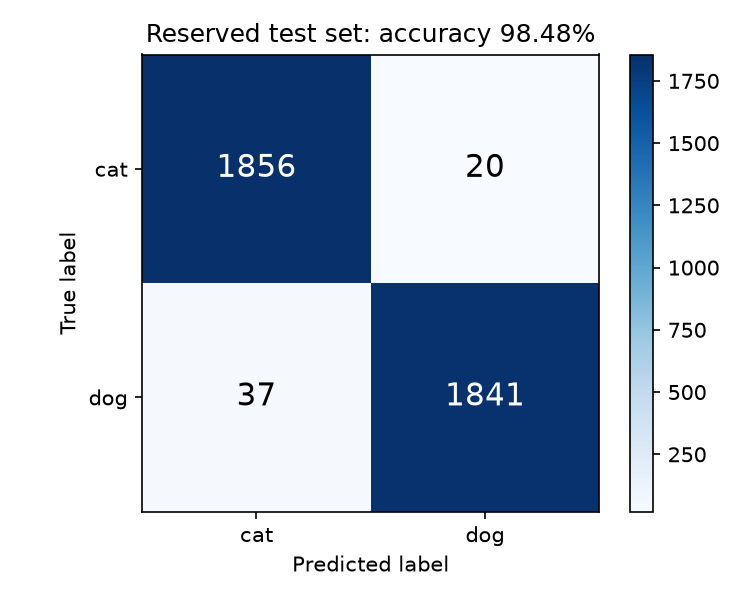

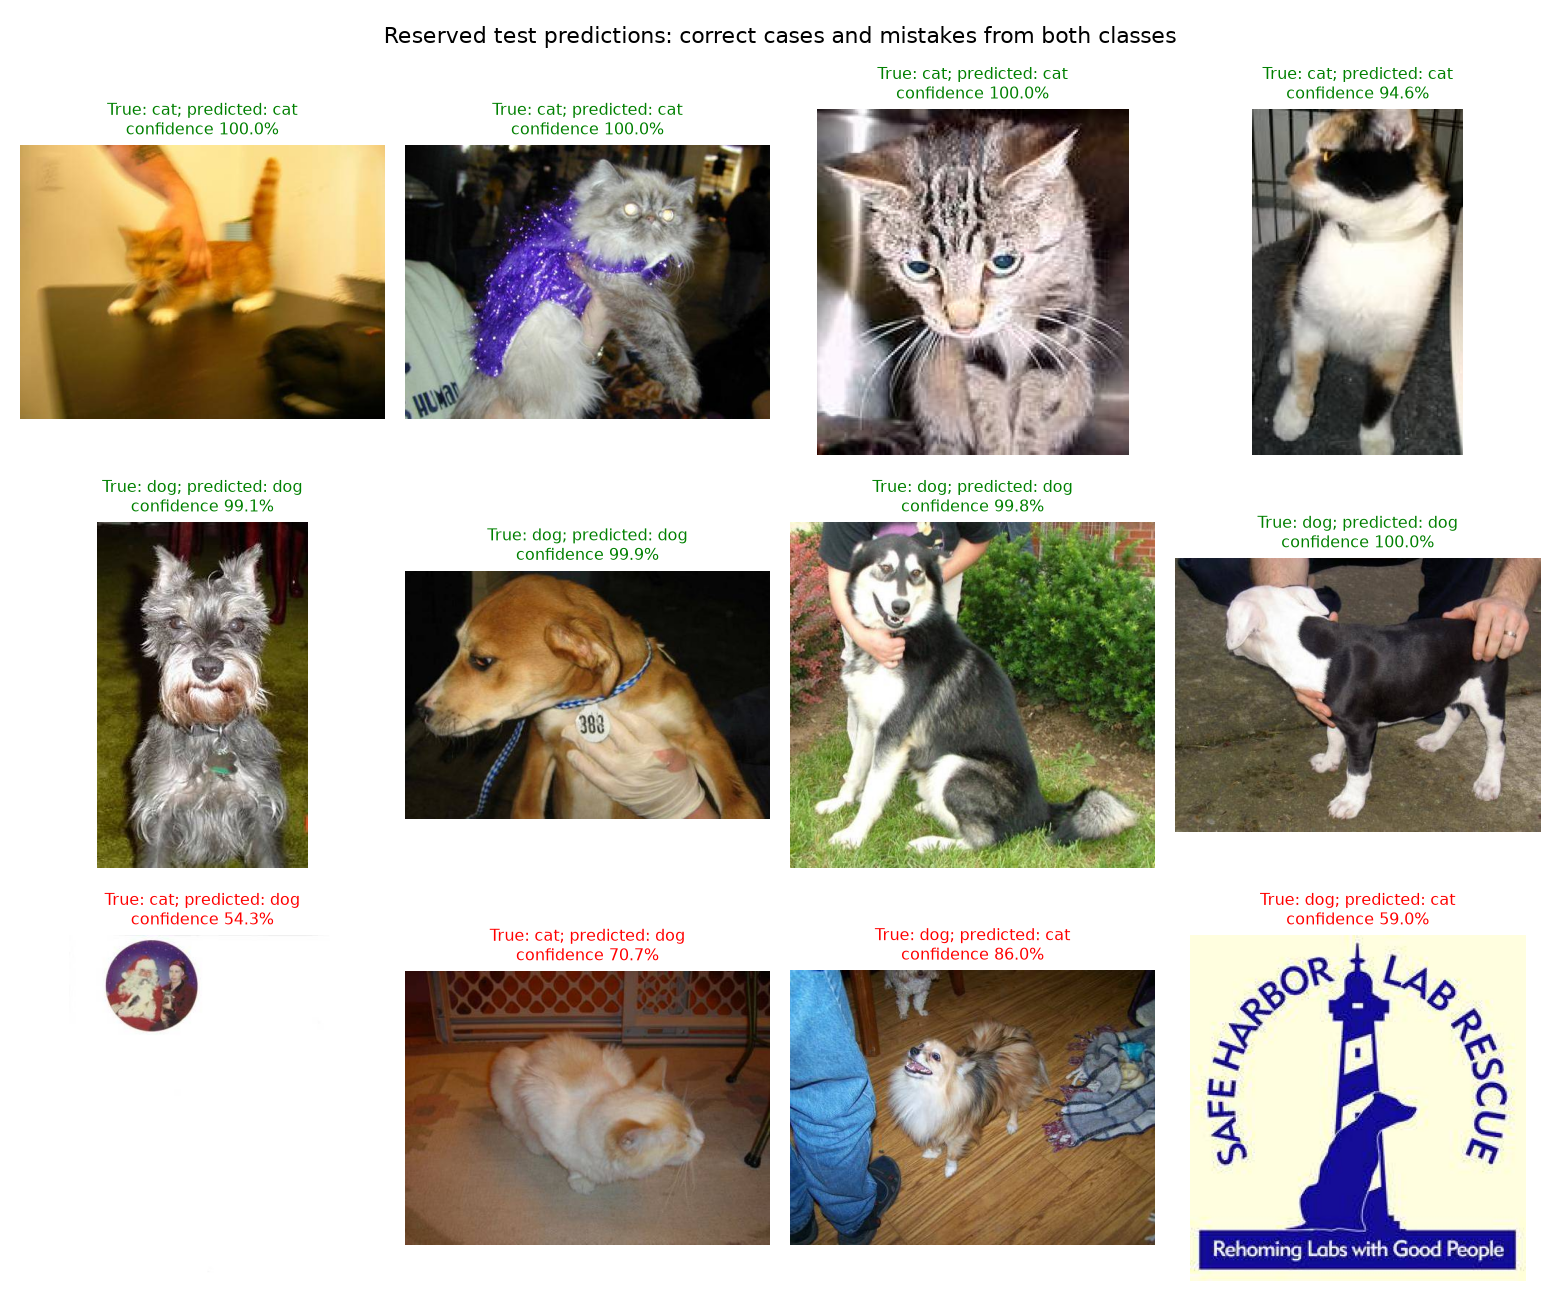

In [7]:
test = report('test_metrics.json')
assert test['selection_locked_before_test']
print('Test photos:', test['test_images'])
print('Accuracy:', f"{test['accuracy']:.2%}")
print('ROC AUC:', round(test['roc_auc'], 5))
print('Log loss:', round(test['log_loss'], 5))
for label in ['cat','dog']:
    print(label, test['classification_report'][label])
figure('confusion_matrix.png')
figure('test_prediction_examples.png')


## Error analysis and limitations

The examples include correct predictions and actual mistakes. Confidence is not a guarantee of correctness. This binary classifier assigns every input to cat or dog and does not reject unrelated images. ImageNet pretraining supplies existing visual knowledge; the final convolutional features were not learned from scratch on this course dataset. Only two head configurations were compared, so the study is a limited optimization exercise rather than an exhaustive search. Results describe this held-out dataset and do not guarantee performance on different camera conditions or populations.


## Predict a new image

From the repository root:
```bash
.venv/bin/python src/app.py --image /path/to/photo.jpg
```
The following smoke check uses a validation photo, not another test-set evaluation.


In [8]:
from data_pipeline import records_for_split
from predict import predict_image
example = ROOT / records_for_split('validation')[0]['path']
print(json.dumps(predict_image(example), indent=2))


I0000 00:00:1794615190.567946   12723 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


{
  "predicted_class": "cat",
  "confidence": 0.9994522929191589,
  "probabilities": {
    "cat": 0.9994522929191589,
    "dog": 0.0005476478254422545
  }
}


## Reproduction and delivery

See the README for environment setup, dataset download, split generation, full training, final evaluation and prediction commands. Large raw data, feature caches, intermediate checkpoints and `.env` remain excluded from Git. The compact final inference model, executed notebooks, histories, plots, metrics and source code are included in the repository.


In [9]:
summary = report('final_run_summary.json')
display(Markdown(f"**Final result:** {summary['test_accuracy']:.2%} accuracy on {summary['test_images']:,} reserved test images. Trained classifier heads on all {summary['training_unique_images']:,} training photos plus {summary['training_augmented_views']:,} training-only augmented views; selected using {summary['validation_images']:,} validation photos."))
print('Saved-model reload passed:', summary['model_reload_passed'])


**Final result:** 98.48% accuracy on 3,754 reserved test images. Trained classifier heads on all 17,498 training photos plus 4,375 training-only augmented views; selected using 3,748 validation photos.

Saved-model reload passed: True
